# 01 — Data Audit (Thành viên A – Khang)
**Đề tài 6 — Ngân hàng: Phát hiện giao dịch thẻ gian lận** · Họ bài toán chính: Phát hiện bất thường

**Mục đích:** xác minh dataset thật (không chép số từ đề), ghi nguồn/giấy phép, mô tả cột, tìm vấn đề chất lượng có bằng chứng, ghi giới hạn dữ liệu, rồi bàn giao cho Cường (B), Quỳnh (C), Huy (D), Mong (E).

**Quy tắc của notebook này**
- Chỉ ĐỌC file raw, không ghi đè (cuối notebook kiểm tra lại checksum).
- Mọi con số trong báo cáo được tính ở đây; các số trong đề (284 807 × 31, 492, 0,172%) chỉ dùng để đối chiếu.
- Chạy từ `notebooks/`, dữ liệu ở `../data/raw/creditcard.csv`.
- Cài thư viện: `pip install pandas numpy matplotlib seaborn scikit-learn`

In [1]:
from pathlib import Path
import hashlib, datetime, json, platform
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
ROOT = Path("..")
DATA_PATH = ROOT / "data" / "raw" / "creditcard.csv"
OUT, FIG = ROOT / "outputs", ROOT / "figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
assert DATA_PATH.exists(), f"Không thấy {DATA_PATH.resolve()} — hãy đặt file CSV vào data/raw/"

M = {}   # nơi gom mọi số đo để ghi ra outputs/audit_metrics.json
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__)

python 3.13.16 | pandas 3.0.2 | numpy 2.5.4 | sklearn 1.8.0


## 1. Nguồn gốc & tính toàn vẹn của file (bước A3)

In [2]:
def file_hash(path, algo):
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

M["file_name"] = DATA_PATH.name
M["file_size_bytes"] = DATA_PATH.stat().st_size
M["sha256"] = file_hash(DATA_PATH, "sha256")
M["md5"] = file_hash(DATA_PATH, "md5")
M["audit_run_date"] = datetime.date.today().isoformat()
for k in ["file_name", "file_size_bytes", "sha256", "md5", "audit_run_date"]:
    print(f"{k:16s}: {M[k]}")
print(f"{'size (MB, 10^6)':16s}: {M['file_size_bytes']/1e6:.1f}")

file_name       : creditcard.csv
file_size_bytes : 150828752
sha256          : 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
md5             : e90efcb83d69faf99fcab8b0255024de
audit_run_date  : 2026-10-26
size (MB, 10^6) : 150.8


**Nguồn (theo bài toán):** Credit Card Fraud Detection — ULB Machine Learning Group, host trên Kaggle  
URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

**Giấy phép — TRẠNG THÁI: ĐÃ XÁC MINH MỘT PHẦN (ảnh chụp Kaggle: "Database: Open Database, Contents: Database Contents" = ODbL + DbCL); còn cần URL, ngày kiểm tra và đọc điều khoản.**
Khang cần mở trang Kaggle, vào mục *License* ở cột bên phải/tab Data, chụp màn hình có ngày giờ, và điền vào bảng dưới (xem thêm `outputs/license_evidence.md`).

| Mục | Giá trị |
|---|---|
| URL đã mở | https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud |
| Ngày kiểm tra | ⟨điền⟩ |
| Tên giấy phép hiển thị trên Kaggle | Database: Open Database, Contents: Database Contents |
| Điều khoản cho phép / hạn chế | ⟨điền sau khi đọc⟩ |
| File ảnh chụp bằng chứng | ⟨vd. outputs/license_screenshot.png⟩ |

## 2. Nạp dữ liệu & số dòng/cột THẬT (bước A4–A5)

In [3]:
df = pd.read_csv(DATA_PATH)
M["n_rows"], M["n_cols"] = map(int, df.shape)
print("shape:", df.shape)
print("cột:", list(df.columns))
print()
df.info()

shape: (284807, 31)
cột: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
print(df.dtypes.value_counts())
# đối chiếu với brief (chỉ tham chiếu, KHÔNG phải nguồn số liệu)
BRIEF = {"rows": 284807, "cols": 31, "fraud": 492}
print("khớp brief về số dòng?", M["n_rows"] == BRIEF["rows"], "| số cột?", M["n_cols"] == BRIEF["cols"])

float64    30
int64       1
Name: count, dtype: int64
khớp brief về số dòng? True | số cột? True


## 3. Nhãn `Class` & mức mất cân bằng

giá trị duy nhất của Class: [np.int64(0), np.int64(1)]
Class
0    284315
1       492
tỷ lệ gian lận: 0.1727%
accuracy nếu đoán 'không gian lận' cho tất cả: 99.827%
khớp brief về số fraud? True


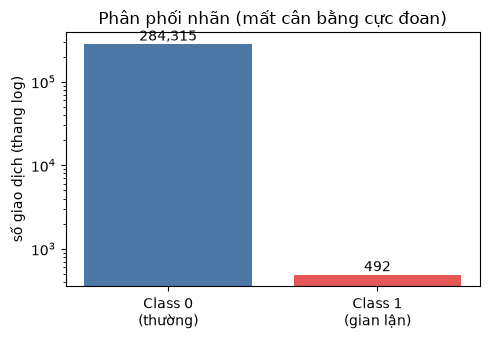

In [6]:
assert "Class" in df.columns
print("giá trị duy nhất của Class:", sorted(df["Class"].unique()))
vc = df["Class"].value_counts().sort_index()
M["n_nonfraud"], M["n_fraud"] = int(vc[0]), int(vc[1])
M["fraud_rate"] = M["n_fraud"] / M["n_rows"]
M["majority_baseline_accuracy"] = M["n_nonfraud"] / M["n_rows"]
print(vc.to_string())
print(f"tỷ lệ gian lận: {M['fraud_rate']*100:.4f}%")
print(f"accuracy nếu đoán 'không gian lận' cho tất cả: {M['majority_baseline_accuracy']*100:.3f}%")
print("khớp brief về số fraud?", M["n_fraud"] == BRIEF["fraud"])

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Class 0\n(thường)", "Class 1\n(gian lận)"], [M["n_nonfraud"], M["n_fraud"]], color=["#4C78A8", "#E45756"])
ax.set_yscale("log"); ax.set_ylabel("số giao dịch (thang log)")
for i, v in enumerate([M["n_nonfraud"], M["n_fraud"]]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Phân phối nhãn (mất cân bằng cực đoan)")
plt.tight_layout(); plt.savefig(FIG / "fig01_label_distribution.png", dpi=150); plt.show()

## 4. Thiếu, trùng lặp, kiểu dữ liệu, miền giá trị (bước A7)

In [7]:
# 4.1 Giá trị thiếu
na = df.isna().sum()
M["n_missing_total"] = int(na.sum())
print("tổng ô thiếu:", M["n_missing_total"], "| cột có thiếu:", list(na[na > 0].index))

tổng ô thiếu: 0 | cột có thiếu: []


In [8]:
# 4.2 Dòng trùng lặp hoàn toàn (tất cả 31 cột giống nhau, kể cả Time)
dup_extra = df.duplicated(keep="first")          # các bản sao thừa
dup_all   = df.duplicated(keep=False)            # mọi dòng thuộc nhóm trùng
M["dup_extra_rows"]        = int(dup_extra.sum())
M["dup_extra_fraud"]       = int(df.loc[dup_extra, "Class"].sum())
M["dup_rows_in_groups"]    = int(dup_all.sum())
M["dup_fraud_in_groups"]   = int(df.loc[dup_all, "Class"].sum())
M["dup_groups"]            = int(df[dup_all].drop_duplicates().shape[0])
print({k: M[k] for k in M if k.startswith("dup_")})
print("\nVí dụ 6 dòng đầu thuộc nhóm trùng:")
df[dup_all].sort_values(list(df.columns)).head(6)[["Time", "V1", "V2", "Amount", "Class"]]

{'dup_extra_rows': 1081, 'dup_extra_fraud': 19, 'dup_rows_in_groups': 1854, 'dup_fraud_in_groups': 32, 'dup_groups': 773}

Ví dụ 6 dòng đầu thuộc nhóm trùng:


,Time,V1,V2,Amount,Class
34,26.0,-0.535388,0.865268,1.77,0
35,26.0,-0.535388,0.865268,1.77,0
32,26.0,-0.529912,0.873892,6.14,0
33,26.0,-0.529912,0.873892,6.14,0
112,74.0,1.038370,0.127486,1.18,0
113,74.0,1.038370,0.127486,1.18,0


In [9]:
# 4.3 Trùng lặp có thể gây rò rỉ khi chia ngẫu nhiên phân tầng (test chứa bản sao của dòng trong train)
tr, te = train_test_split(df, test_size=0.3, stratify=df["Class"], random_state=RANDOM_STATE)
h = lambda x: pd.util.hash_pandas_object(x, index=False)
in_train = h(te).isin(set(h(tr)))
M["leak_test_rows"]       = int(len(te))
M["leak_test_dup_in_train"]       = int(in_train.sum())
M["leak_test_fraud"]      = int(te["Class"].sum())
M["leak_test_fraud_dup_in_train"] = int(te.loc[in_train.values, "Class"].sum())
print(f"Split 70/30 stratify, random_state=42: {M['leak_test_dup_in_train']:,}/{M['leak_test_rows']:,} dòng test có bản sao y hệt trong train;"
      f" trong đó fraud: {M['leak_test_fraud_dup_in_train']}/{M['leak_test_fraud']}")

Split 70/30 stratify, random_state=42: 456/85,443 dòng test có bản sao y hệt trong train; trong đó fraud: 7/148


In [10]:
# 4.4 Miền giá trị & giá trị bất khả thi
M["amount_zero_rows"]  = int((df["Amount"] == 0).sum())
M["amount_zero_fraud"] = int(df.loc[df["Amount"] == 0, "Class"].sum())
M["amount_negative"]   = int((df["Amount"] < 0).sum())
M["amount_max"]        = float(df["Amount"].max())
M["time_min"], M["time_max"] = float(df["Time"].min()), float(df["Time"].max())
M["time_non_integer"]  = int((df["Time"] != df["Time"].round()).sum())
M["time_sorted"]       = bool(df["Time"].is_monotonic_increasing)
M["time_ties"]         = int(df["Time"].duplicated().sum())
M["amount_decimals_gt2"] = int(((df["Amount"] * 100).round(6) % 1 != 0).sum())
print(f"Amount: min={df.Amount.min()}, max={M['amount_max']:,.2f}, âm={M['amount_negative']}, =0: {M['amount_zero_rows']:,} (fraud {M['amount_zero_fraud']})")
print(f"Amount có >2 chữ số thập phân: {M['amount_decimals_gt2']}")
print(f"Time: {M['time_min']:.0f} → {M['time_max']:.0f} giây = {M['time_max']/3600:.3f} giờ; không nguyên: {M['time_non_integer']}; đã sắp tăng dần: {M['time_sorted']}; dòng trùng Time với dòng trước: {M['time_ties']:,}")
print(f"Tỷ lệ fraud trong nhóm Amount=0: {M['amount_zero_fraud']/M['amount_zero_rows']*100:.2f}%  (toàn bộ: {M['fraud_rate']*100:.3f}%)")

Amount: min=0.0, max=25,691.16, âm=0, =0: 1,825 (fraud 27)
Amount có >2 chữ số thập phân: 0
Time: 0 → 172792 giây = 47.998 giờ; không nguyên: 0; đã sắp tăng dần: True; dòng trùng Time với dòng trước: 160,215
Tỷ lệ fraud trong nhóm Amount=0: 1.48%  (toàn bộ: 0.173%)


## 5. Các cột `V1…V28` (đã qua PCA — không diễn giải ý nghĩa nghiệp vụ)

In [11]:
V = [f"V{i}" for i in range(1, 29)]
desc = df[V].describe().T[["mean", "std", "min", "max"]]
corr = df[V].corr().values
off = np.abs(corr - np.eye(len(V)))
M["v_max_abs_offdiag_corr"] = float(off.max())
M["v_max_abs_mean"] = float(desc["mean"].abs().max())
print(f"|mean| lớn nhất của V*: {M['v_max_abs_mean']:.2e}  |  tương quan chéo lớn nhất giữa các V*: {M['v_max_abs_offdiag_corr']:.2e}")
print("→ nhất quán với mô tả của nguồn là các thành phần PCA (trung bình ≈ 0, không tương quan). Đây KHÔNG chứng minh ý nghĩa của từng V.")
print(f"std giảm dần từ V1={desc.loc['V1','std']:.3f} đến V28={desc.loc['V28','std']:.3f}")

z = (df[V] - df[V].mean()) / df[V].std()
big = (z.abs() > 10).any(axis=1)
M["rows_any_V_abs_z_gt10"]       = int(big.sum())
M["fraud_rows_any_V_abs_z_gt10"] = int(df.loc[big, "Class"].sum())
print(f"Dòng có ít nhất 1 V* với |z|>10: {M['rows_any_V_abs_z_gt10']:,} (trong đó fraud: {M['fraud_rows_any_V_abs_z_gt10']}/{M['n_fraud']})")
desc.round(3)

|mean| lớn nhất của V*: 4.87e-15  |  tương quan chéo lớn nhất giữa các V*: 2.32e-14
→ nhất quán với mô tả của nguồn là các thành phần PCA (trung bình ≈ 0, không tương quan). Đây KHÔNG chứng minh ý nghĩa của từng V.
std giảm dần từ V1=1.959 đến V28=0.330
Dòng có ít nhất 1 V* với |z|>10: 1,924 (trong đó fraud: 231/492)


,mean,std,min,max
V1,0.0,1.959,-56.408,2.455
V2,0.0,1.651,-72.716,22.058
V3,-0.0,1.516,-48.326,9.383
V4,0.0,1.416,-5.683,16.875
V5,0.0,1.380,-113.743,34.802
V6,0.0,1.332,-26.161,73.302
V7,-0.0,1.237,-43.557,120.589
V8,0.0,1.194,-73.217,20.007
V9,-0.0,1.099,-13.434,15.595
V10,0.0,1.089,-24.588,23.745


## 6. `Amount`: phân phối lệch nặng, nhưng KHÔNG xoá outlier

skew=16.98, kurtosis=845.1; hàng rào IQR=184.51
Vượt hàng rào IQR: 31,904 dòng (fraud: 91)
          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87
              n  fraud  fraud_rate_%
Amount                              
0          1825     27         1.479
0–10      98439    222         0.226
10–50     90781     57         0.063
50–100    37254     56         0.150
100–500   47366     95         0.201
500–1000   6202     26         0.419
>1000      2940      9         0.306


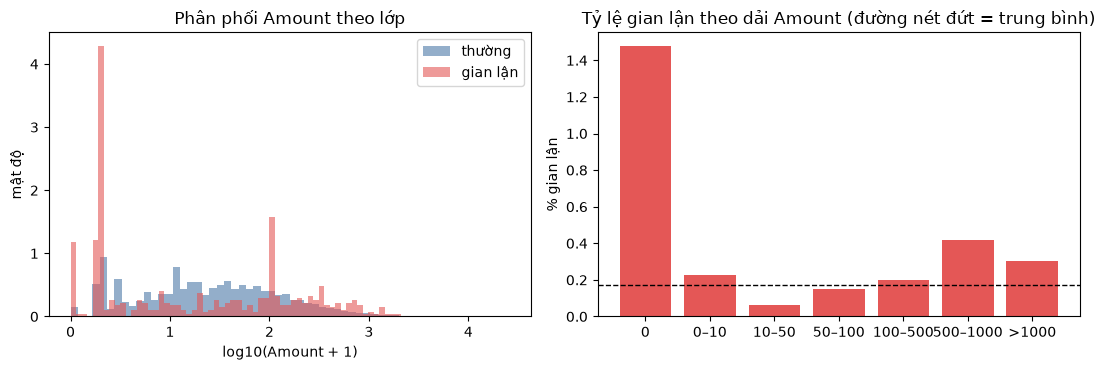

In [12]:
M["amount_skew"] = float(df["Amount"].skew()); M["amount_kurtosis"] = float(df["Amount"].kurt())
q1, q3 = df["Amount"].quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
iqr_out = df["Amount"] > fence
M["amount_iqr_fence"] = float(fence)
M["amount_iqr_outliers"] = int(iqr_out.sum()); M["amount_iqr_outliers_fraud"] = int(df.loc[iqr_out, "Class"].sum())
print(f"skew={M['amount_skew']:.2f}, kurtosis={M['amount_kurtosis']:.1f}; hàng rào IQR={fence:.2f}")
print(f"Vượt hàng rào IQR: {M['amount_iqr_outliers']:,} dòng (fraud: {M['amount_iqr_outliers_fraud']})")
print(df.groupby("Class")["Amount"].describe().round(2))

bands = pd.cut(df["Amount"], [-0.01, 0, 10, 50, 100, 500, 1000, 1e9],
               labels=["0", "0–10", "10–50", "50–100", "100–500", "500–1000", ">1000"])
bt = df.groupby(bands, observed=True)["Class"].agg(n="size", fraud="sum")
bt["fraud_rate_%"] = (bt["fraud"] / bt["n"] * 100).round(3)
bt.to_csv(OUT / "amount_band_fraud_rate.csv")
M["amount_bands"] = bt.reset_index().astype({"Amount": str}).to_dict("records")
print(bt)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for c, col, name in [(0, "#4C78A8", "thường"), (1, "#E45756", "gian lận")]:
    ax[0].hist(np.log10(df.loc[df.Class == c, "Amount"] + 1), bins=60, alpha=.6, color=col, density=True, label=name)
ax[0].set_xlabel("log10(Amount + 1)"); ax[0].set_ylabel("mật độ"); ax[0].legend(); ax[0].set_title("Phân phối Amount theo lớp")
ax[1].bar(bt.index.astype(str), bt["fraud_rate_%"], color="#E45756")
ax[1].axhline(M["fraud_rate"] * 100, ls="--", c="k", lw=1); ax[1].set_ylabel("% gian lận"); ax[1].set_title("Tỷ lệ gian lận theo dải Amount (đường nét đứt = trung bình)")
plt.tight_layout(); plt.savefig(FIG / "fig02_amount.png", dpi=150); plt.show()

In [13]:
# Các mức Amount lặp lại nhiều nhất trong lớp gian lận (quan sát mô tả, KHÔNG suy ra nguyên nhân)
top_f = df.loc[df.Class == 1, "Amount"].value_counts().head(5)
M["fraud_amount_top_values"] = {str(k): int(v) for k, v in top_f.items()}
M["fraud_share_amount_exactly_1"] = float((df.loc[df.Class == 1, "Amount"] == 1.0).mean())
print("Top 5 mức Amount trong lớp fraud:", M["fraud_amount_top_values"])
print(f"Fraud có Amount đúng 1.00: {M['fraud_amount_top_values'].get('1.0', 0)}/{M['n_fraud']} = {M['fraud_share_amount_exactly_1']*100:.1f}%")
print("Mức 1.00 trong lớp thường:", int((df.loc[df.Class == 0, "Amount"] == 1.0).sum()), "dòng")

Top 5 mức Amount trong lớp fraud: {'1.0': 113, '0.0': 27, '99.99': 27, '0.76': 17, '0.77': 10}
Fraud có Amount đúng 1.00: 113/492 = 23.0%
Mức 1.00 trong lớp thường: 13575 dòng


## 7. `Time` — giây tương đối so với giao dịch đầu tiên, KHÔNG phải timestamp
Theo mô tả của nguồn, `Time` là số giây kể từ giao dịch đầu tiên trong dataset. Dữ liệu không cho biết giao dịch đầu tiên xảy ra lúc mấy giờ, ngày nào.
Vì vậy "giờ trong ngày" thật **không** suy ra được; chỉ có "giờ kể từ lúc bắt đầu" (0–47) và "ngày tương đối" (0 hoặc 1).

           n  fraud
Time               
0     144786    281
1     140021    211


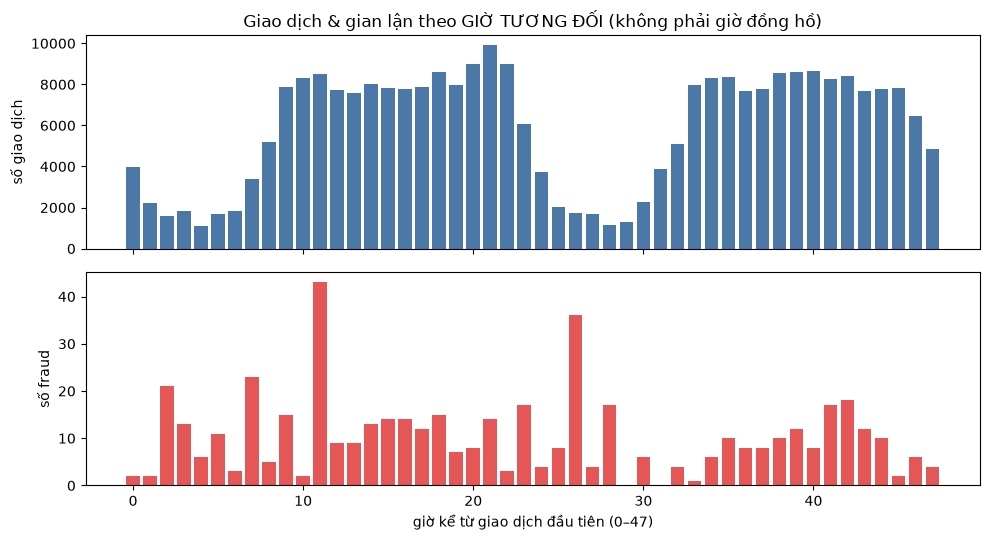

Cảnh báo: số fraud mỗi giờ rất nhỏ (xem cột fraud) → tỷ lệ theo giờ dao động mạnh; không kết luận 'ban đêm rủi ro hơn'.


,n,fraud,fraud_rate_%
Time,,,
26,1752,36,2.055
28,1127,17,1.508
2,1576,21,1.332
3,1821,13,0.714
7,3368,23,0.683


In [14]:
rel_hour = (df["Time"] // 3600).astype(int)          # 0..47, giờ kể từ giao dịch đầu
rel_day  = (df["Time"] // 86400).astype(int)         # 0 hoặc 1 (giả định: ranh giới tại 86 400 giây)
cyc_hour = rel_hour % 24                              # chu kỳ 24h TƯƠNG ĐỐI, không phải giờ đồng hồ

day_tbl = df.groupby(rel_day)["Class"].agg(n="size", fraud="sum")
M["day_table"] = day_tbl.reset_index().rename(columns={"Time": "rel_day"}).to_dict("records")
print(day_tbl)

hr = df.groupby(rel_hour)["Class"].agg(n="size", fraud="sum"); hr["fraud_rate_%"] = (hr["fraud"] / hr["n"] * 100).round(3)
hr.to_csv(OUT / "relative_hour_fraud_rate.csv")
fig, ax = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax[0].bar(hr.index, hr["n"], color="#4C78A8"); ax[0].set_ylabel("số giao dịch")
ax[1].bar(hr.index, hr["fraud"], color="#E45756"); ax[1].set_ylabel("số fraud"); ax[1].set_xlabel("giờ kể từ giao dịch đầu tiên (0–47)")
ax[0].set_title("Giao dịch & gian lận theo GIỜ TƯƠNG ĐỐI (không phải giờ đồng hồ)")
plt.tight_layout(); plt.savefig(FIG / "fig03_relative_hour.png", dpi=150); plt.show()
print("Cảnh báo: số fraud mỗi giờ rất nhỏ (xem cột fraud) → tỷ lệ theo giờ dao động mạnh; không kết luận 'ban đêm rủi ro hơn'.")
hr.sort_values("fraud_rate_%", ascending=False).head(5)

## 8. Đầu vào cho câu hỏi nghiệp vụ: "ngân sách rà soát 100 giao dịch / ngày"
Tính **trần lý thuyết**: ngay cả một bộ xếp hạng hoàn hảo cũng chỉ bắt được tối đa `min(100, số fraud trong ngày)` mỗi ngày.
(Định nghĩa "ngày" = mỗi 86 400 giây kể từ giao dịch đầu tiên là **một giả định cần cả nhóm chốt**, xem mục I.5 của tài liệu nhóm.)

In [15]:
cap = 100
ceil_per_day = day_tbl["fraud"].clip(upper=cap)
M["review_cap_per_day"] = cap
M["max_caught_by_perfect_ranker"] = int(ceil_per_day.sum())
M["max_recall_perfect_ranker_100_per_day"] = float(ceil_per_day.sum() / M["n_fraud"])
M["avg_fraud_per_day"] = float(M["n_fraud"] / day_tbl.shape[0])
M["avg_txn_per_day"]   = float(M["n_rows"] / day_tbl.shape[0])
M["review_share_of_daily_txn"] = float(cap / M["avg_txn_per_day"])
print(f"Fraud/ngày: {day_tbl['fraud'].to_dict()}  (trung bình {M['avg_fraud_per_day']:.0f}/ngày) vs ngân sách {cap}/ngày")
print(f"Trần recall của bộ xếp hạng HOÀN HẢO với 100/ngày = {M['max_caught_by_perfect_ranker']}/{M['n_fraud']} = {M['max_recall_perfect_ranker_100_per_day']*100:.2f}%")
print(f"100 giao dịch = {M['review_share_of_daily_txn']*100:.3f}% lượng giao dịch trung bình mỗi ngày ({M['avg_txn_per_day']:,.0f})")

Fraud/ngày: {0: 281, 1: 211}  (trung bình 246/ngày) vs ngân sách 100/ngày
Trần recall của bộ xếp hạng HOÀN HẢO với 100/ngày = 200/492 = 40.65%
100 giao dịch = 0.070% lượng giao dịch trung bình mỗi ngày (142,404)


## 9. Bảng vấn đề chất lượng dữ liệu (bước A8) — sinh tự động từ số đo ở trên

In [16]:
Q = []
def add(i, name, evidence, consequence, handling, risk, approver, status="Có bằng chứng"):
    Q.append(dict(ID=i, Van_de=name, Trang_thai=status, Bang_chung=evidence, Anh_huong=consequence,
                  Phuong_an_de_xuat=handling, Rui_ro_neu_xu_ly_sai=risk, Nguoi_duyet=approver))

add("DQ-01", "Dòng trùng lặp hoàn toàn",
    f"{M['dup_extra_rows']:,} bản sao thừa ({M['dup_rows_in_groups']:,} dòng thuộc {M['dup_groups']} nhóm trùng); trong bản sao thừa có {M['dup_extra_fraud']} fraud. "
    f"Với split 70/30 stratify random_state=42: {M['leak_test_dup_in_train']:,}/{M['leak_test_rows']:,} dòng test có bản sao trong train (fraud {M['leak_test_fraud_dup_in_train']}/{M['leak_test_fraud']}).",
    "Chia ngẫu nhiên làm test lọt bản sao của dòng train → số đo (nhất là LOF/k-NN, mô hình ghi nhớ) có thể đẹp giả; cũng làm lệch đếm giao dịch/fraud khi OLAP.",
    "Cường quyết định: (a) khử trùng TRƯỚC khi chia và ghi decision log, hoặc (b) giữ nguyên nhưng báo cáo số đo kèm/không kèm bản sao. Không xoá âm thầm.",
    f"Khử trùng làm mất {M['dup_extra_fraud']} nhãn fraud ({M['dup_extra_fraud']/M['n_fraud']*100:.1f}% tổng fraud) và đổi tổng số dòng; mọi con số phải nhất quán giữa notebook/SQL/dashboard.",
    "Cường (B) + Khang; thông báo Quỳnh, Huy, Mong")

add("DQ-02", "Amount = 0 (giá trị đáng ngờ, không rõ ý nghĩa)",
    f"{M['amount_zero_rows']:,} dòng có Amount=0, trong đó {M['amount_zero_fraud']} fraud (tỷ lệ fraud {M['amount_zero_fraud']/M['amount_zero_rows']*100:.2f}% so với {M['fraud_rate']*100:.3f}% toàn bộ).",
    "Nguồn không giải thích Amount=0 là gì (có thể là giao dịch kiểm tra/xác thực — chỉ là giả thuyết, KHÔNG được khẳng định). Log/chuẩn hoá Amount có thể lỗi hoặc gộp nhóm này.",
    "Giữ nguyên dòng; dùng log1p hoặc scaler chịu được 0; cân nhắc cờ is_zero_amount và ghi decision log.",
    "Xoá nhóm này sẽ mất 27 fraud và một nhóm có tỷ lệ fraud cao hơn ~8,6 lần trung bình.",
    "Cường (B)")

add("DQ-03", "Mất cân bằng lớp cực đoan",
    f"{M['n_fraud']} fraud / {M['n_rows']:,} = {M['fraud_rate']*100:.4f}%. Đoán 'không gian lận' cho tất cả đạt accuracy {M['majority_baseline_accuracy']*100:.3f}%.",
    "Accuracy vô nghĩa; split ngẫu nhiên không phân tầng có thể cho test rất ít/không có fraud.",
    "Dùng stratified split/k-fold, Precision@k, PR-AUC, Recall; ghi baseline (xếp hạng ngẫu nhiên, đoán đa số).",
    "Chọn sai chỉ số → kết luận sai ở tiêu chí 7 (★).",
    "Huy (D) + Mong (E)")

add("DQ-04", "Amount lệch phải nặng, đuôi dài",
    f"skew={M['amount_skew']:.1f}, kurtosis={M['amount_kurtosis']:.0f}; max={M['amount_max']:,.2f}; {M['amount_iqr_outliers']:,} dòng vượt hàng rào IQR ({M['amount_iqr_fence']:.1f}), trong đó {M['amount_iqr_outliers_fraud']} fraud.",
    "Mô hình/khoảng cách bị Amount chi phối nếu không biến đổi; boxplot thô khó đọc.",
    "Biến đổi (log1p hoặc RobustScaler) fit trên train; KHÔNG xoá outlier (theo bài học tuần 2).",
    "Xoá outlier theo phản xạ làm mất các ca cần phát hiện.",
    "Cường (B)")

add("DQ-05", "Time là giây tương đối, không phải thời điểm thực; kiểu float cho giá trị nguyên",
    f"Time: {M['time_min']:.0f}–{M['time_max']:.0f} s (= {M['time_max']/3600:.3f} giờ ≈ 2 ngày); {M['time_non_integer']} giá trị không nguyên (dtype float64); {M['time_ties']:,} dòng trùng Time với dòng trước. Không có cột ngày/giờ/đơn vị tiền.",
    "Không thể có 'giờ trong ngày' hay ngày lịch thật → đề xuất 'Time → giờ trong ngày' và `date_key` trong brief không có căn cứ nếu hiểu là giờ đồng hồ. Ranh giới 'ngày' (86 400 s) là giả định.",
    "Dùng 'giờ tương đối' (0–47) và 'ngày tương đối' (0/1); đặt tên Dim rõ là *tương đối*; có thể ép Time về int.",
    "Gọi 'ban đêm/ban ngày' hay gắn ngày lịch giả sẽ là bịa ý nghĩa.",
    "Cả nhóm (cần xác nhận mục I.3 của tài liệu nhóm); Quỳnh khi thiết kế Dim_Date/Dim_Hour")

add("DQ-06", "Khác thang đo & đuôi nặng giữa Time/Amount và V1–V28",
    f"std: V1={desc.loc['V1','std']:.2f} … V28={desc.loc['V28','std']:.2f}, trong khi Amount≈250, Time≈{df['Time'].std():,.0f}. {M['rows_any_V_abs_z_gt10']:,} dòng có |z|>10 ở ít nhất một V*, chứa {M['fraud_rows_any_V_abs_z_gt10']}/{M['n_fraud']} fraud ({M['fraud_rows_any_V_abs_z_gt10']/M['n_fraud']*100:.1f}%).",
    "LOF/k-NN dựa khoảng cách sẽ bị Time/Amount lấn át nếu không chuẩn hoá; đuôi nặng ở V* vừa là nhiễu vừa là tín hiệu fraud.",
    "Chuẩn hoá trong pipeline, fit trên train/fold; cân nhắc có đưa Time vào mô hình không (ghi decision log).",
    "Fit scaler trên toàn bộ dữ liệu = leakage; xoá |z|>10 = mất ~47% fraud.",
    "Cường (B), Huy (D)")

add("DQ-07", "Thiếu siêu dữ liệu: không có mã thẻ/khách/cửa hàng/kênh/quốc gia/đơn vị tiền",
    f"31 cột chỉ gồm Time, V1–V28, Amount, Class. Không cột nhóm nhân khẩu hay kênh thanh toán.",
    "Dim_Channel trong brief chỉ có thể là dữ liệu mô phỏng; không đo được công bằng theo nhóm người; không chắc đơn vị tiền của Amount.",
    "Ghi rõ Dim_Channel là synthetic (hoặc hỏi giảng viên trước khi dùng); công bằng chỉ đo được theo dải Amount/thời gian tương đối.",
    "Trình bày dimension mô phỏng như dữ liệu thật = vi phạm tiêu chí 10 (liêm chính).",
    "Quỳnh (C) + Khang; hỏi giảng viên nếu nghi ngờ")

add("CHK-01", "Giá trị thiếu (đã kiểm tra, KHÔNG phát hiện)",
    f"Tổng ô thiếu = {M['n_missing_total']}; không có Amount âm ({M['amount_negative']}).",
    "Không cần imputation.", "Không xử lý; không tính vào số vấn đề tối thiểu.", "—", "—", status="Đã kiểm tra, không có vấn đề")

qdf = pd.DataFrame(Q); qdf.to_csv(OUT / "quality_issues.csv", index=False, encoding="utf-8-sig")
M["n_quality_issues_with_evidence"] = int((qdf["Trang_thai"] == "Có bằng chứng").sum())
print("số vấn đề có bằng chứng:", M["n_quality_issues_with_evidence"])
qdf[["ID", "Van_de", "Trang_thai", "Bang_chung"]]

số vấn đề có bằng chứng: 7


,ID,Van_de,Trang_thai,Bang_chung
0,DQ-01,Dòng trùng lặp hoàn toàn,Có bằng chứng,"1,081 bản sao thừa (1,854 dòng thuộc 773 nhóm ..."
1,DQ-02,"Amount = 0 (giá trị đáng ngờ, không rõ ý nghĩa)",Có bằng chứng,"1,825 dòng có Amount=0, trong đó 27 fraud (tỷ ..."
2,DQ-03,Mất cân bằng lớp cực đoan,Có bằng chứng,"492 fraud / 284,807 = 0.1727%. Đoán 'không gia..."
3,DQ-04,"Amount lệch phải nặng, đuôi dài",Có bằng chứng,"skew=17.0, kurtosis=845; max=25,691.16; 31,904..."
4,DQ-05,"Time là giây tương đối, không phải thời điểm t...",Có bằng chứng,Time: 0–172792 s (= 47.998 giờ ≈ 2 ngày); 0 gi...
5,DQ-06,Khác thang đo & đuôi nặng giữa Time/Amount và ...,Có bằng chứng,"std: V1=1.96 … V28=0.33, trong khi Amount≈250,..."
6,DQ-07,Thiếu siêu dữ liệu: không có mã thẻ/khách/cửa ...,Có bằng chứng,"31 cột chỉ gồm Time, V1–V28, Amount, Class. Kh..."
7,CHK-01,"Giá trị thiếu (đã kiểm tra, KHÔNG phát hiện)","Đã kiểm tra, không có vấn đề",Tổng ô thiếu = 0; không có Amount âm (0).


## 10. Data dictionary (bước A6) — mô tả chỉ lấy từ những gì nguồn nêu; phần còn lại ghi rõ là giới hạn

In [17]:
SRC = "Mô tả trên trang dataset (mirror của mô tả Kaggle/ULB); cần Khang đối chiếu với trang Kaggle gốc"
meaning = {
    "Time":   ("đặc trưng gốc (không PCA)", "Số giây kể từ giao dịch đầu tiên trong dataset.", "Không phải timestamp; không biết giờ/ngày thật của giao dịch đầu; chỉ dùng như thời gian TƯƠNG ĐỐI."),
    "Amount": ("đặc trưng gốc (không PCA)", "Số tiền giao dịch.", "Nguồn không nêu đơn vị tiền tệ; lệch phải rất nặng; có 1 825 giá trị 0 không rõ ý nghĩa."),
    "Class":  ("nhãn", "Biến phản hồi: 1 = gian lận, 0 = ngược lại.", "Chỉ dùng để đánh giá (và cho mô hình giám sát); KHÔNG đưa vào feature của mô hình không giám sát."),
}
rows = []
for c in df.columns:
    s = df[c]
    if c in meaning: role, d, lim = meaning[c]
    else: role, d, lim = ("thành phần PCA (ẩn danh)", "Một trong các thành phần chính (principal component) do PCA tạo ra từ các đặc trưng gốc đã bị ẩn vì bảo mật.",
                          "Không có ý nghĩa nghiệp vụ biết được; KHÔNG gán nghĩa (vd. V14); chỉ dùng như số liệu ẩn danh.")
    rows.append(dict(cot=c, dtype_quan_sat=str(s.dtype), vai_tro=role, mo_ta=d, nguon_mo_ta=SRC,
                     so_thieu=int(s.isna().sum()), so_gia_tri_duy_nhat=int(s.nunique()),
                     min=float(s.min()), max=float(s.max()), mean=float(s.mean()), std=float(s.std()),
                     vi_du=", ".join(map(str, s.head(3).tolist())), gioi_han_dien_giai=lim))
dd = pd.DataFrame(rows); dd.to_csv(OUT / "data_dictionary.csv", index=False, encoding="utf-8-sig")
print(dd.shape); dd.head(4)

(31, 13)


,cot,dtype_quan_sat,vai_tro,mo_ta,nguon_mo_ta,so_thieu,so_gia_tri_duy_nhat,min,max,mean,std,vi_du,gioi_han_dien_giai
0,Time,float64,đặc trưng gốc (không PCA),Số giây kể từ giao dịch đầu tiên trong dataset.,Mô tả trên trang dataset (mirror của mô tả Kag...,0,124592,0.000000,172792.000000,9.481386e+04,47488.145955,"0.0, 0.0, 1.0",Không phải timestamp; không biết giờ/ngày thật...
1,V1,float64,thành phần PCA (ẩn danh),Một trong các thành phần chính (principal comp...,Mô tả trên trang dataset (mirror của mô tả Kag...,0,275663,-56.407510,2.454930,1.175161e-15,1.958696,"-1.3598071336738, 1.19185711131486, -1.3583540...",Không có ý nghĩa nghiệp vụ biết được; KHÔNG gá...
2,V2,float64,thành phần PCA (ẩn danh),Một trong các thành phần chính (principal comp...,Mô tả trên trang dataset (mirror của mô tả Kag...,0,275663,-72.715728,22.057729,3.384974e-16,1.651309,"-0.0727811733098497, 0.26615071205963, -1.3401...",Không có ý nghĩa nghiệp vụ biết được; KHÔNG gá...
3,V3,float64,thành phần PCA (ẩn danh),Một trong các thành phần chính (principal comp...,Mô tả trên trang dataset (mirror của mô tả Kag...,0,275663,-48.325589,9.382558,-1.379537e-15,1.516255,"2.53634673796914, 0.16648011335321, 1.77320934...",Không có ý nghĩa nghiệp vụ biết được; KHÔNG gá...


## 11. Giới hạn dữ liệu (bước A9)
1. **Lịch sử, hẹp:** ~2 ngày, thẻ châu Âu, tháng 9/2013 (theo mô tả nguồn) → không suy rộng sang hành vi hiện tại hay thị trường khác; nghiên cứu "suy giảm theo thời gian" chỉ có 2 điểm (ngày 0 và ngày 1).
2. **Mất cân bằng cực đoan** (xem §3) và **trần recall 100/ngày** (xem §8).
3. **V1–V28 ẩn danh:** không diễn giải nghiệp vụ; mọi "feature importance" của V* không nói được điều gì về hành vi thật.
4. **Time tương đối**, không có đơn vị tiền, không có mã thẻ/khách/cửa hàng/kênh → không đo công bằng theo nhóm người được; không có khái niệm "một khách hàng nhiều giao dịch".
5. **Nhãn từ hệ thống thật:** nguồn không nêu quy trình gán nhãn; có thể bỏ sót fraud chưa bị phát hiện (nhãn 0 không bảo đảm "thật sự sạch") — đây là giới hạn chung của dữ liệu fraud, nguồn dữ liệu gốc không cho thêm thông tin.

## 12. Kiểm tra cuối: file raw không bị thay đổi & ghi số đo

In [18]:
M["sha256_after"] = file_hash(DATA_PATH, "sha256")
assert M["sha256_after"] == M["sha256"], "File raw đã bị thay đổi!"
print("OK — checksum raw không đổi:", M["sha256_after"])
with open(OUT / "audit_metrics.json", "w", encoding="utf-8") as f:
    json.dump(M, f, ensure_ascii=False, indent=2)
print("đã ghi:", sorted(p.name for p in OUT.iterdir()))

OK — checksum raw không đổi: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
đã ghi: ['amount_band_fraud_rate.csv', 'audit_metrics.json', 'data_audit_summary.md', 'data_dictionary.csv', 'license_evidence.md', 'quality_issues.csv', 'relative_hour_fraud_rate.csv']
